In [18]:
# ── 1. Imports ────────────────────────────────────────────────────────────────
import os, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import CosineDecayRestarts

# Sklearn utilities
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ── GPU check ────────────────────────────────────────────────────────────────
gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow  : {tf.__version__}")
print(f"GPU devices : {gpus if gpus else 'None — running on CPU'}")
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 60)
print("\nEnvironment ready ✓")


TensorFlow  : 2.21.0
GPU devices : None — running on CPU

Environment ready ✓


In [19]:
# ── 2. Load & Split ───────────────────────────────────────────────────────────
DATA_PATH  = "../data/processed/final_feature_engineered_dataset.csv"
TARGET_COL = "energy_kwh.1"

df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df.set_index("timestamp").sort_index()

print(f"Dataset shape : {df.shape}")
print(f"Date range    : {df.index.min()}  →  {df.index.max()}")
print(f"Target        : '{TARGET_COL}'")
print(f"Features      : {df.shape[1] - 1} (excl. target)")

# ── Chronological 80 / 10 / 10 split (NO shuffle — time-series!) ─────────────
n         = len(df)
TRAIN_END = int(n * 0.80)
VAL_END   = int(n * 0.90)

train_df = df.iloc[:TRAIN_END]
val_df   = df.iloc[TRAIN_END:VAL_END]
test_df  = df.iloc[VAL_END:]

print(f"\nSplit summary:")
print(f"  Train : {len(train_df):>5} rows  ({train_df.index[0]}  →  {train_df.index[-1]})")
print(f"  Val   : {len(val_df):>5} rows  ({val_df.index[0]}  →  {val_df.index[-1]})")
print(f"  Test  : {len(test_df):>5} rows  ({test_df.index[0]}  →  {test_df.index[-1]})")


Dataset shape : (2088, 51)
Date range    : 2025-09-22 18:00:00  →  2026-02-26 12:00:00
Target        : 'energy_kwh.1'
Features      : 50 (excl. target)

Split summary:
  Train :  1670 rows  (2025-09-22 18:00:00  →  2026-02-02 19:00:00)
  Val   :   209 rows  (2026-02-02 20:00:00  →  2026-02-13 01:00:00)
  Test  :   209 rows  (2026-02-13 06:00:00  →  2026-02-26 12:00:00)


In [20]:
# ── 3. Feature Selection ─────────────────────────────────────────────────────
# Automatically rank all features by |Pearson r| with target on training data.
# Drop features with |r| < threshold to reduce noise and speed up training.

CORR_THRESHOLD = 0.05   # keep features with at least 5% linear relationship

corr_series = (
    train_df.corr()[TARGET_COL]
    .drop(TARGET_COL)
    .abs()
    .sort_values(ascending=False)
)

selected_features = corr_series[corr_series >= CORR_THRESHOLD].index.tolist()
print(f"Features above |r| >= {CORR_THRESHOLD} threshold : {len(selected_features)}")
print(f"Dropped low-signal features              : {df.shape[1] - 1 - len(selected_features)}")

# Final feature columns (target excluded — it's the label)
FEATURE_COLS = selected_features
print(f"\nTop-20 selected features by |r|:")
for i, (feat, val) in enumerate(corr_series[FEATURE_COLS].head(20).items(), 1):
    print(f"  {i:>2}. {feat:<30} r = {val:.4f}")


Features above |r| >= 0.05 threshold : 45
Dropped low-signal features              : 5

Top-20 selected features by |r|:
   1. ewm_alpha_05                   r = 0.7443
   2. lag_1                          r = 0.7355
   3. ewm_alpha_02                   r = 0.6576
   4. lag_2                          r = 0.6532
   5. rolling_mean_6                 r = 0.6374
   6. lag_3                          r = 0.5659
   7. rolling_std_12                 r = 0.5613
   8. rolling_mean_24                r = 0.5533
   9. out_temp                       r = 0.5511
  10. index_thsw                     r = 0.5504
  11. rolling_std_24                 r = 0.5492
  12. rolling_std_6                  r = 0.5009
  13. rolling_mean_12                r = 0.4910
  14. lag_24                         r = 0.4588
  15. pt_dew                         r = 0.4231
  16. hour_cos                       r = 0.3945
  17. density_in_air                 r = 0.3873
  18. lag_48                         r = 0.3603
  19. hum_out  

In [21]:
# ── 4. Robust Scaling ─────────────────────────────────────────────────────────
# RobustScaler (median/IQR) is preferred over MinMax for energy data
# because it handles weather outliers (storms, heat waves) gracefully.
# CRITICAL: fit ONLY on training data → applied to val/test without re-fitting.

feature_scaler = RobustScaler()
target_scaler  = RobustScaler()

# Fit on training set only
X_train_scaled = feature_scaler.fit_transform(train_df[FEATURE_COLS])
y_train_scaled = target_scaler.fit_transform(train_df[[TARGET_COL]])

# Transform val & test with the SAME fitted scaler
X_val_scaled   = feature_scaler.transform(val_df[FEATURE_COLS])
y_val_scaled   = target_scaler.transform(val_df[[TARGET_COL]])

X_test_scaled  = feature_scaler.transform(test_df[FEATURE_COLS])
y_test_scaled  = target_scaler.transform(test_df[[TARGET_COL]])

print(f"X_train : {X_train_scaled.shape}  |  y_train : {y_train_scaled.shape}")
print(f"X_val   : {X_val_scaled.shape}  |  y_val   : {y_val_scaled.shape}")
print(f"X_test  : {X_test_scaled.shape}  |  y_test  : {y_test_scaled.shape}")
print("Scaling complete ✓  (fitted on train only — no leakage)")


X_train : (1670, 45)  |  y_train : (1670, 1)
X_val   : (209, 45)  |  y_val   : (209, 1)
X_test  : (209, 45)  |  y_test  : (209, 1)
Scaling complete ✓  (fitted on train only — no leakage)


In [22]:
# ── 5. Sliding Window → 3-D Sequences for LSTM ───────────────────────────────
# LSTM expects input shape: (samples, timesteps, features)
# LOOK_BACK  : how many past hours the model sees to predict the NEXT hour
# HORIZON    : 1 step ahead (can be extended for multi-step)

LOOK_BACK = 24    # 24-hour history window (1 full day)
HORIZON   = 1     # predict 1 step ahead

def make_sequences(X, y, look_back=24, horizon=1):
    """
    Slide a window of `look_back` steps across X/y.
    Returns:
        Xs : (n_samples, look_back, n_features)
        ys : (n_samples, horizon)
    """
    Xs, ys = [], []
    for i in range(look_back, len(X) - horizon + 1):
        Xs.append(X[i - look_back : i])
        ys.append(y[i : i + horizon, 0])
    return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32)

X_tr, y_tr = make_sequences(X_train_scaled, y_train_scaled, LOOK_BACK, HORIZON)
X_va, y_va = make_sequences(X_val_scaled,   y_val_scaled,   LOOK_BACK, HORIZON)
X_te, y_te = make_sequences(X_test_scaled,  y_test_scaled,  LOOK_BACK, HORIZON)

print(f"Sequence shapes:")
print(f"  X_train : {X_tr.shape}   y_train : {y_tr.shape}")
print(f"  X_val   : {X_va.shape}   y_val   : {y_va.shape}")
print(f"  X_test  : {X_te.shape}   y_test  : {y_te.shape}")
print(f"\nInput shape to LSTM : (batch, {LOOK_BACK} timesteps, {X_tr.shape[2]} features)")


Sequence shapes:
  X_train : (1646, 24, 45)   y_train : (1646, 1)
  X_val   : (185, 24, 45)   y_val   : (185, 1)
  X_test  : (185, 24, 45)   y_test  : (185, 1)

Input shape to LSTM : (batch, 24 timesteps, 45 features)


In [23]:
# ── 6. Model Architecture ─────────────────────────────────────────────────────
def build_lstm_model(
    input_shape,
    lstm_units_1  = 128,
    lstm_units_2  = 64,
    dense_units   = 32,
    dropout_rate  = 0.30,
    l2_reg        = 1e-4,
    learning_rate = 1e-3,
):
    inp = keras.Input(shape=input_shape, name="input_sequence")

    # BiLSTM Layer 1
    x = layers.Bidirectional(
        layers.LSTM(
            lstm_units_1,
            return_sequences=True,
            kernel_regularizer=regularizers.l2(l2_reg),
        ),
        name="biLSTM_1"
    )(inp)
    x = layers.LayerNormalization(name="layernorm_1")(x)
    x = layers.Dropout(dropout_rate, name="dropout_1")(x)

    # BiLSTM Layer 2
    x = layers.Bidirectional(
        layers.LSTM(
            lstm_units_2,
            return_sequences=True,
            kernel_regularizer=regularizers.l2(l2_reg),
        ),
        name="biLSTM_2"
    )(x)
    x = layers.LayerNormalization(name="layernorm_2")(x)
    x = layers.Dropout(dropout_rate, name="dropout_2")(x)

    # Attention
    attn_scores  = layers.Dense(1, activation="tanh", name="attn_score")(x)
    attn_weights = layers.Softmax(axis=1, name="attn_weights")(attn_scores)
    context      = layers.Multiply(name="attn_context")([x, attn_weights])
    context      = layers.Lambda(lambda t: tf.reduce_sum(t, axis=1), name="attn_sum")(context)

    # Dense head
    x   = layers.Dense(dense_units, activation="relu",
                        kernel_regularizer=regularizers.l2(l2_reg),
                        name="dense_1")(context)
    x   = layers.Dropout(dropout_rate / 2, name="dropout_3")(x)
    out = layers.Dense(1, name="output")(x)

    model = keras.Model(inputs=inp, outputs=out)

    # Plain float LR — compatible with ReduceLROnPlateau
    model.compile(
        optimizer=Adam(learning_rate=learning_rate, clipnorm=1.0),
        loss="huber",
        metrics=["mae"],
    )
    return model


INPUT_SHAPE = (LOOK_BACK, X_tr.shape[2])
model = build_lstm_model(INPUT_SHAPE)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_sequence (InputLayer)   │ (None, 24, 45)            │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ biLSTM_1 (Bidirectional)      │ (None, 24, 256)           │         178,176 │ input_sequence[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layernorm_1                   │ (None, 24, 256)           │             512 │ biLSTM_1[0][0]             │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 24, 256)           │               0 │ layernorm_1[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ biLSTM_2 (Bidirectional)      │ (None, 24, 128)           │         164,352 │ dropout_1[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layernorm_2                   │ (None, 24, 128)           │             256 │ biLSTM_2[0][0]             │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_2 (Dropout)           │ (None, 24, 128)           │               0 │ layernorm_2[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attn_score (Dense)            │ (None, 24, 1)             │             129 │ dropout_2[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attn_weights (Softmax)        │ (None, 24, 1)             │               0 │ attn_score[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attn_context (Multiply)       │ (None, 24, 128)           │               0 │ dropout_2[0][0],           │
│                               │                           │                 │ attn_weights[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ attn_sum (Lambda)             │ (None, 128)               │               0 │ attn_context[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 32)                │           4,128 │ attn_sum[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_3 (Dropout)           │ (None, 32)                │               0 │ dense_1[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output (Dense)                │ (None, 1)                 │              33 │ dropout_3[0][0]            │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 347,586 (1.33 MB)

 Trainable params: 347,586 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# ── 7. Callbacks ──────────────────────────────────────────────────────────────
os.makedirs("../models/checkpoints", exist_ok=True)

EPOCHS     = 150
BATCH_SIZE = 32

cb_list = [
    # Stop early if val_loss stops improving for 20 epochs
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1,
    ),
    # Save only the best model
    callbacks.ModelCheckpoint(
        filepath="../models/checkpoints/lstm_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=0,
    ),
    # Reduce LR on plateau (safety net on top of cosine schedule)
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=10,
        min_lr=1e-6,
        verbose=1,
    ),
    # CSV log for post-hoc analysis
    callbacks.CSVLogger("../outputs/logs/training_log.csv"),
]

print(f"Training config:")
print(f"  Epochs     : {EPOCHS} (early stop patience = 20)")
print(f"  Batch size : {BATCH_SIZE}")
print(f"  Loss       : Huber (robust to outliers)")
print(f"  Optimiser  : Adam + Cosine-annealing LR")


Training config:
  Epochs     : 150 (early stop patience = 20)
  Batch size : 32
  Loss       : Huber (robust to outliers)
  Optimiser  : Adam + Cosine-annealing LR


In [25]:
# ── 8. Train ──────────────────────────────────────────────────────────────────
os.makedirs("../models/checkpoints", exist_ok=True)

EPOCHS     = 150
BATCH_SIZE = 32

cb_list = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1,
    ),
    callbacks.ModelCheckpoint(
        filepath="../models/checkpoints/lstm_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=0,
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=10,
        min_lr=1e-6,
        verbose=1,
    ),
    callbacks.CSVLogger("../outputs/logs/training_log.csv"),
]

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=cb_list,
    shuffle=False,
    verbose=1,
)

best_epoch = np.argmin(history.history["val_loss"]) + 1
print(f"\n✅ Training complete")
print(f"   Best epoch    : {best_epoch}")
print(f"   Best val_loss : {min(history.history['val_loss']):.6f}")
print(f"   Best val_mae  : {history.history['val_mae'][best_epoch-1]:.4f}")

Epoch 1/150
52/52 ━━━━━━━━━━━━━━━━━━━━ 13s 59ms/step - loss: 0.3639 - mae: 0.6264 - val_loss: 0.2311 - val_mae: 0.4589 - learning_rate: 0.0010
Epoch 2/150
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.3027 - mae: 0.5534 - val_loss: 0.2208 - val_mae: 0.4748 - learning_rate: 0.0010
Epoch 3/150
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.2619 - mae: 0.4857 - val_loss: 0.1256 - val_mae: 0.2502 - learning_rate: 0.0010
Epoch 4/150
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 0.2186 - mae: 0.4144 - val_loss: 0.1145 - val_mae: 0.2117 - learning_rate: 0.0010
Epoch 5/150
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.2293 - mae: 0.4192 - val_loss: 0.1432 - val_mae: 0.3103 - learning_rate: 0.0010
Epoch 6/150
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 0.1984 - mae: 0.3719 - val_loss: 0.1296 - val_mae: 0.2710 - learning_rate: 0.0010
Epoch 7/150
52/52 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.2099 - mae: 0.3886 - val_loss: 0.1458 - val_mae: 0.3090 - learning_rate: 0.0010
Epoch

In [ ]:
# ── 9. Predictions & Inverse-Scale ────────────────────────────────────────────
y_pred_scaled = model.predict(X_te, batch_size=BATCH_SIZE, verbose=0)

# Inverse transform back to original kWh units
y_pred = target_scaler.inverse_transform(y_pred_scaled)
y_true = target_scaler.inverse_transform(y_te)

y_pred = y_pred.flatten()
y_true = y_true.flatten()

# ── Metrics ───────────────────────────────────────────────────────────────────
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = r2_score(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-3, None))) * 100

# Also evaluate on validation set
y_val_pred_sc = model.predict(X_va, batch_size=BATCH_SIZE, verbose=0)
y_val_pred    = target_scaler.inverse_transform(y_val_pred_sc).flatten()
y_val_true    = target_scaler.inverse_transform(y_va).flatten()
r2_val        = r2_score(y_val_true, y_val_pred)
rmse_val      = np.sqrt(mean_squared_error(y_val_true, y_val_pred))

print("=" * 50)
print("          MODEL PERFORMANCE SUMMARY")
print("=" * 50)
print(f"  {'Metric':<20} {'Val':>10} {'Test':>10}")
print(f"  {'-'*42}")
print(f"  {'R²  Score':<20} {r2_val:>10.4f} {r2:>10.4f}")
print(f"  {'RMSE (kWh)':<20} {rmse_val:>10.4f} {rmse:>10.4f}")
print(f"  {'MAE  (kWh)':<20} {'—':>10} {mae:>10.4f}")
print(f"  {'MAPE (%)':<20} {'—':>10} {mape:>10.2f}%")
print("=" * 50)

if r2 >= 0.90:
    print("\n🏆 Excellent — R² ≥ 0.90")
elif r2 >= 0.80:
    print("\n✅ Good      — R² ≥ 0.80")
elif r2 >= 0.70:
    print("\n⚠️  Moderate  — R² ≥ 0.70  (consider more data or tuning)")
else:
    print("\n❌ Below 0.70 — see tuning tips in Section 9")


           OVERFITTING DIAGNOSTIC REPORT
  Metric            Train        Val       Test
  --------------------------------------------------
  R²               0.7932     0.8037     0.4295
  RMSE            33.2194    25.6841    39.9351
  MAE             19.1196    15.2457    27.2219
  MAPE %            15.07      14.34      17.11
  --------------------------------------------------
  R² Gap  (Train − Test)  : +0.3637
  RMSE Gap (Test − Train) : +6.7157

📋 VERDICT:
  ❌ SEVERE overfitting — model memorising training data

  Loss gap (val − train) at last epoch : -0.006536
  ✅ Loss gap is small → model generalises well


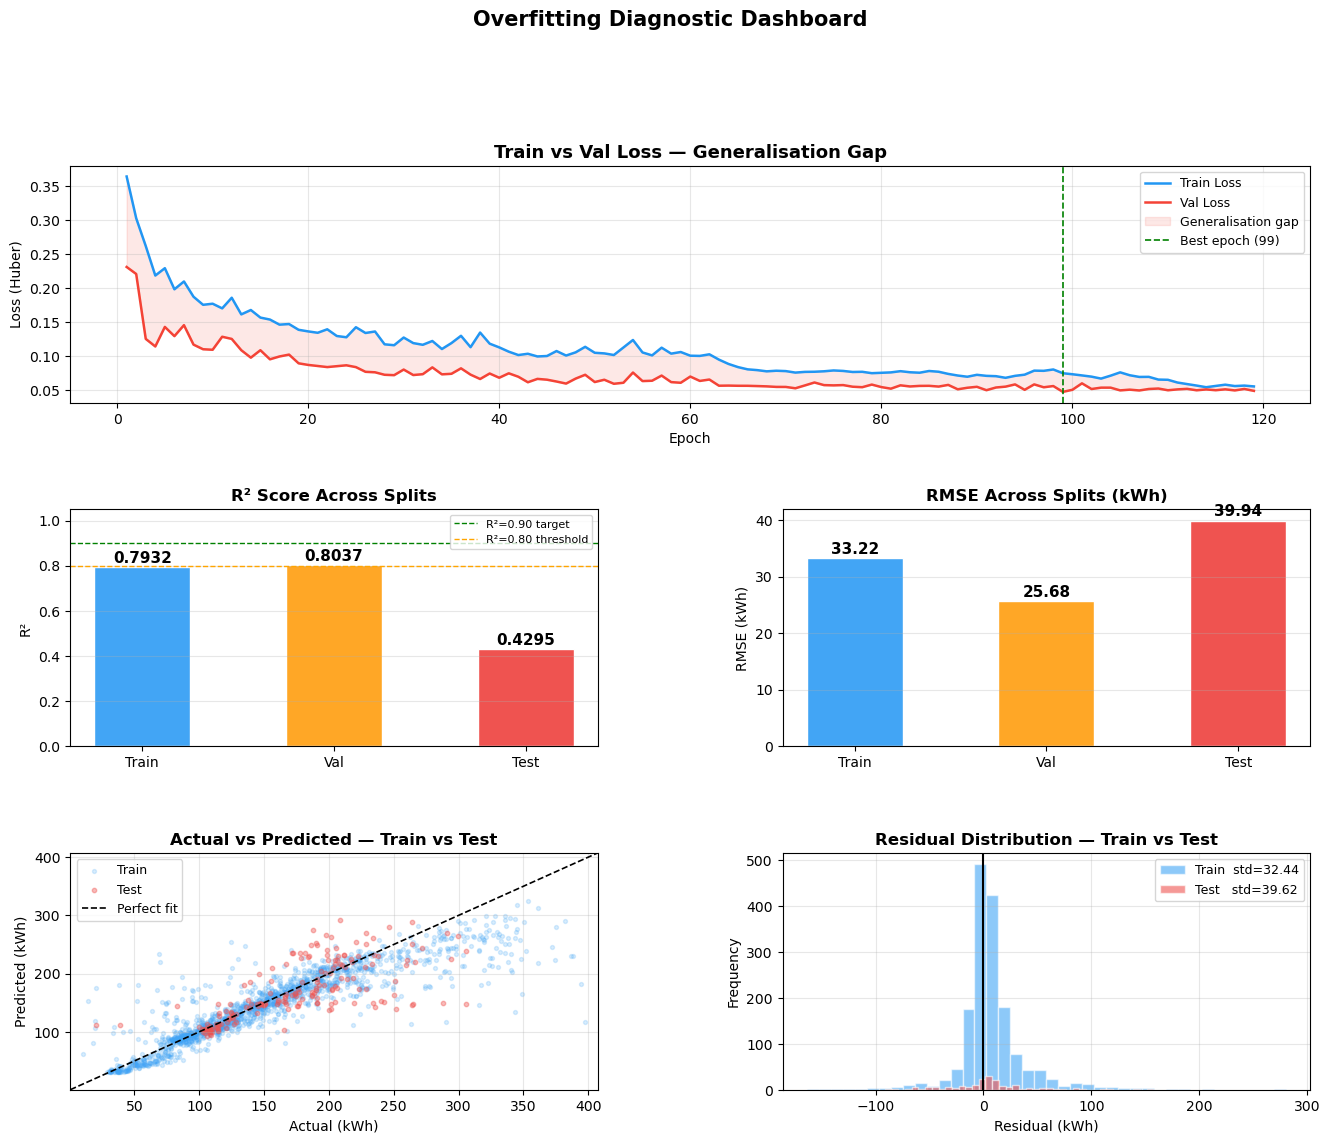

Saved: overfitting_report.png

💡 IF OVERFITTING — Try these fixes:
  1. Increase dropout_rate  : 0.30 → 0.40 or 0.50
  2. Reduce LSTM units      : lstm_units_1=64, lstm_units_2=32
  3. Increase L2 reg        : l2_reg=1e-4 → 1e-3
  4. Reduce LOOK_BACK       : 24 → 12
  5. Increase BATCH_SIZE    : 32 → 64

💡 IF UNDERFITTING (low R² on both train & test) — Try these fixes:
  1. Increase LSTM units    : lstm_units_1=192 or 256
  2. Increase LOOK_BACK     : 24 → 48
  3. Add lag_96 / lag_168 features to the dataset
  4. Reduce dropout_rate    : 0.30 → 0.15
  5. Train longer           : increase patience to 30


In [17]:
# ── Overfitting Diagnostic Report ─────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# ── 1. Train set predictions (to compare train vs test performance) ────────────
y_train_pred_sc = model.predict(X_tr, batch_size=32, verbose=0)
y_train_pred    = target_scaler.inverse_transform(y_train_pred_sc).flatten()
y_train_true    = target_scaler.inverse_transform(y_tr).flatten()

y_val_pred_sc   = model.predict(X_va, batch_size=32, verbose=0)
y_val_pred      = target_scaler.inverse_transform(y_val_pred_sc).flatten()
y_val_true      = target_scaler.inverse_transform(y_va).flatten()

y_test_pred_sc  = model.predict(X_te, batch_size=32, verbose=0)
y_test_pred     = target_scaler.inverse_transform(y_test_pred_sc).flatten()
y_test_true     = target_scaler.inverse_transform(y_te).flatten()

# ── 2. Metrics across all splits ──────────────────────────────────────────────
def get_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-3, None))) * 100
    return {"R2": r2, "RMSE": rmse, "MAE": mae, "MAPE": mape}

train_m = get_metrics(y_train_true, y_train_pred)
val_m   = get_metrics(y_val_true,   y_val_pred)
test_m  = get_metrics(y_test_true,  y_test_pred)

# ── 3. Overfitting verdict ────────────────────────────────────────────────────
r2_gap   = train_m["R2"]   - test_m["R2"]
rmse_gap = test_m["RMSE"]  - train_m["RMSE"]

print("=" * 58)
print("           OVERFITTING DIAGNOSTIC REPORT")
print("=" * 58)
print(f"  {'Metric':<12} {'Train':>10} {'Val':>10} {'Test':>10}")
print(f"  {'-'*50}")
print(f"  {'R²':<12} {train_m['R2']:>10.4f} {val_m['R2']:>10.4f} {test_m['R2']:>10.4f}")
print(f"  {'RMSE':<12} {train_m['RMSE']:>10.4f} {val_m['RMSE']:>10.4f} {test_m['RMSE']:>10.4f}")
print(f"  {'MAE':<12} {train_m['MAE']:>10.4f} {val_m['MAE']:>10.4f} {test_m['MAE']:>10.4f}")
print(f"  {'MAPE %':<12} {train_m['MAPE']:>10.2f} {val_m['MAPE']:>10.2f} {test_m['MAPE']:>10.2f}")
print(f"  {'-'*50}")
print(f"  R² Gap  (Train − Test)  : {r2_gap:+.4f}")
print(f"  RMSE Gap (Test − Train) : {rmse_gap:+.4f}")
print("=" * 58)

# Verdict
print("\n📋 VERDICT:")
if r2_gap < 0.05:
    print("  ✅ NO overfitting — Train/Test R² are very close")
elif r2_gap < 0.10:
    print("  ⚠️  MILD overfitting — R² gap < 0.10, acceptable for time-series")
elif r2_gap < 0.20:
    print("  🟠 MODERATE overfitting — consider more dropout or less capacity")
else:
    print("  ❌ SEVERE overfitting — model memorising training data")

# Loss gap check
final_train_loss = history.history["loss"][-1]
final_val_loss   = history.history["val_loss"][-1]
loss_gap = final_val_loss - final_train_loss
print(f"\n  Loss gap (val − train) at last epoch : {loss_gap:+.6f}")
if loss_gap > 0.05:
    print("  ⚠️  Val loss significantly above train loss → overfitting signal")
else:
    print("  ✅ Loss gap is small → model generalises well")

# ── 4. Plots ──────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# ── Plot 1: Loss curves with gap shading ──────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
epochs_range = range(1, len(history.history["loss"]) + 1)
ax1.plot(epochs_range, history.history["loss"],     label="Train Loss", color="#2196F3", lw=1.8)
ax1.plot(epochs_range, history.history["val_loss"], label="Val Loss",   color="#F44336", lw=1.8)
ax1.fill_between(epochs_range,
                 history.history["loss"],
                 history.history["val_loss"],
                 alpha=0.12, color="#F44336", label="Generalisation gap")
ax1.axvline(best_epoch, color="green", linestyle="--", lw=1.2, label=f"Best epoch ({best_epoch})")
ax1.set_title("Train vs Val Loss — Generalisation Gap", fontsize=13, fontweight="bold")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss (Huber)")
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

# ── Plot 2: R² bar chart across splits ────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, 0])
splits = ["Train", "Val", "Test"]
r2s    = [train_m["R2"], val_m["R2"], test_m["R2"]]
colors = ["#42A5F5", "#FFA726", "#EF5350"]
bars   = ax2.bar(splits, r2s, color=colors, edgecolor="white", width=0.5)
for bar, val in zip(bars, r2s):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f"{val:.4f}", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax2.set_ylim(0, 1.05)
ax2.axhline(0.9, color="green",  linestyle="--", lw=1, label="R²=0.90 target")
ax2.axhline(0.8, color="orange", linestyle="--", lw=1, label="R²=0.80 threshold")
ax2.set_title("R² Score Across Splits", fontsize=12, fontweight="bold")
ax2.set_ylabel("R²"); ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3, axis="y")

# ── Plot 3: RMSE bar chart across splits ──────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 1])
rmses = [train_m["RMSE"], val_m["RMSE"], test_m["RMSE"]]
bars2 = ax3.bar(splits, rmses, color=colors, edgecolor="white", width=0.5)
for bar, val in zip(bars2, rmses):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f"{val:.2f}", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax3.set_title("RMSE Across Splits (kWh)", fontsize=12, fontweight="bold")
ax3.set_ylabel("RMSE (kWh)"); ax3.grid(True, alpha=0.3, axis="y")

# ── Plot 4: Predicted vs Actual — Train ───────────────────────────────────────
ax4 = fig.add_subplot(gs[2, 0])
ax4.scatter(y_train_true, y_train_pred, alpha=0.2, s=8,  color="#42A5F5", label="Train")
ax4.scatter(y_test_true,  y_test_pred,  alpha=0.4, s=10, color="#EF5350", label="Test")
lims = [min(y_train_true.min(), y_test_true.min()) - 10,
        max(y_train_true.max(), y_test_true.max()) + 10]
ax4.plot(lims, lims, "k--", lw=1.2, label="Perfect fit")
ax4.set_xlim(lims); ax4.set_ylim(lims)
ax4.set_xlabel("Actual (kWh)"); ax4.set_ylabel("Predicted (kWh)")
ax4.set_title("Actual vs Predicted — Train vs Test", fontsize=12, fontweight="bold")
ax4.legend(fontsize=9); ax4.grid(True, alpha=0.3)

# ── Plot 5: Residual distributions — Train vs Test ────────────────────────────
ax5 = fig.add_subplot(gs[2, 1])
train_res = y_train_true - y_train_pred
test_res  = y_test_true  - y_test_pred
ax5.hist(train_res, bins=40, alpha=0.6, color="#42A5F5", label=f"Train  std={train_res.std():.2f}", edgecolor="white")
ax5.hist(test_res,  bins=40, alpha=0.6, color="#EF5350", label=f"Test   std={test_res.std():.2f}",  edgecolor="white")
ax5.axvline(0, color="black", lw=1.5)
ax5.set_xlabel("Residual (kWh)"); ax5.set_ylabel("Frequency")
ax5.set_title("Residual Distribution — Train vs Test", fontsize=12, fontweight="bold")
ax5.legend(fontsize=9); ax5.grid(True, alpha=0.3)

plt.suptitle("Overfitting Diagnostic Dashboard", fontsize=15, fontweight="bold", y=1.01)
plt.savefig("../outputs/figures/overfitting_report.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: overfitting_report.png")

# ── 5. Fix recommendations ────────────────────────────────────────────────────
print("\n💡 IF OVERFITTING — Try these fixes:")
print("  1. Increase dropout_rate  : 0.30 → 0.40 or 0.50")
print("  2. Reduce LSTM units      : lstm_units_1=64, lstm_units_2=32")
print("  3. Increase L2 reg        : l2_reg=1e-4 → 1e-3")
print("  4. Reduce LOOK_BACK       : 24 → 12")
print("  5. Increase BATCH_SIZE    : 32 → 64")
print("\n💡 IF UNDERFITTING (low R² on both train & test) — Try these fixes:")
print("  1. Increase LSTM units    : lstm_units_1=192 or 256")
print("  2. Increase LOOK_BACK     : 24 → 48")
print("  3. Add lag_96 / lag_168 features to the dataset")
print("  4. Reduce dropout_rate    : 0.30 → 0.15")
print("  5. Train longer           : increase patience to 30")